In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df=pd.read_csv("c:/Users/ROHAN/Downloads/D61. Wardwise Covid beds_3_cleaned.csv")
df.head()


,City Name,Area Name,Day-Month-Year,Ward No.,Ward Name,Type of hospital_PrivateorPublic,Longitude,Latitude,Total no. of beds,Number of COVID beds,Number of ICU beds,Number of ventilators or ABD
0,Kalyan Dombivali,DOMBIVLI West,44573,63,Kopar Road,Apurva Hospital Private,73.13,19.236,15.0,NaN,NaN,NaN
1,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Life Line Hospital Private,73.13,19.236,23.0,NaN,6.0,NaN
2,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apex Hospital Private,73.13,19.236,26.0,NaN,4.0,1.0
3,Kalyan Dombivali,DOMBIVLI West,44573,61,Vishnu Nagar,Apple Hospital Private,73.13,19.236,27.0,10.0,9.0,3.0
4,Kalyan Dombivali,DOMBIVLI West,44573,59,Kanhoji Jedhe Maidan,Spandan Hospital Private,73.13,19.236,22.0,8.0,4.0,NaN


In [10]:
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   City Name                         181 non-null    str    
 1   Area Name                         179 non-null    str    
 2   Day-Month-Year                    176 non-null    str    
 3   Ward No.                          169 non-null    str    
 4   Ward Name                         179 non-null    str    
 5   Type of hospital_PrivateorPublic  168 non-null    str    
 6   Longitude                         111 non-null    str    
 7   Latitude                          111 non-null    str    
 8   Total no. of beds                 143 non-null    float64
 9   Number of COVID beds              111 non-null    float64
 10  Number of ICU beds                133 non-null    float64
 11  Number of ventilators or ABD      111 non-null    float64
dtypes: float64(4), str(

City Name                               str
Area Name                               str
Day-Month-Year                          str
Ward No.                                str
Ward Name                               str
Type of hospital_PrivateorPublic        str
Longitude                               str
Latitude                                str
Total no. of beds                   float64
Number of COVID beds                float64
Number of ICU beds                  float64
Number of ventilators or ABD        float64
dtype: object

In [12]:
plt.figure(figsize=(10,5))
sns.set_style("whitegrid")

<Figure size 1000x500 with 0 Axes>

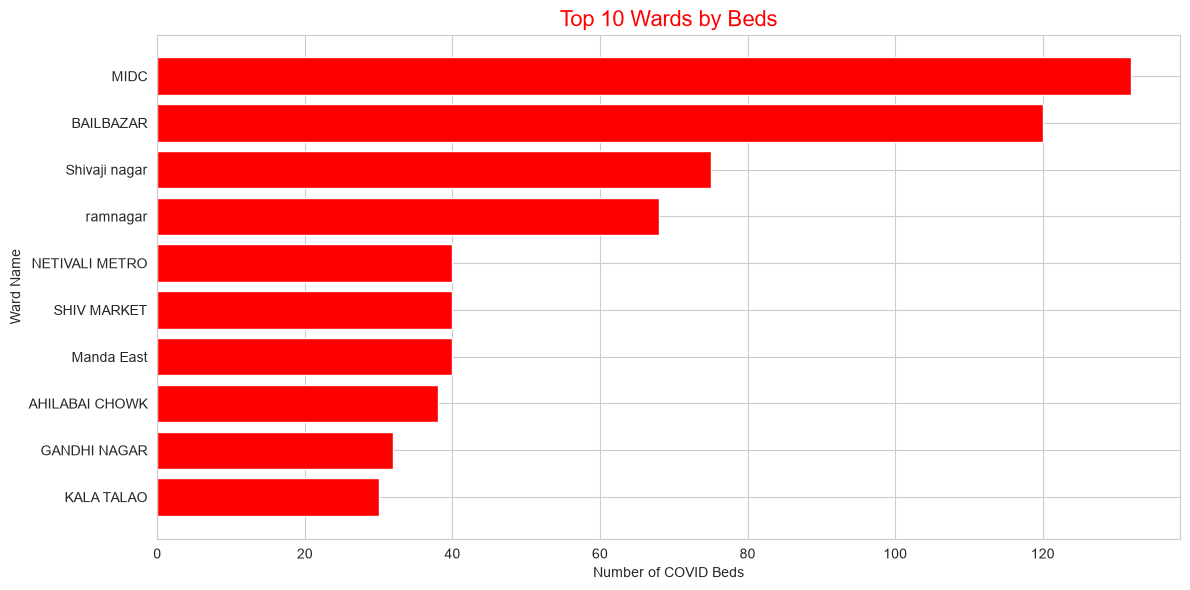

In [36]:
ward_beds= df.groupby("Ward Name")["Number of COVID beds"].sum()
top_10=ward_beds.sort_values(ascending=False).head(10)
plt.figure(figsize=(12,6))
plt.barh(top_10.index, top_10.values, color="Red")
plt.title("Top 10 Wards by Beds", fontsize=16 , color="red")
plt.xlabel("Number of COVID Beds")
plt.ylabel("Ward Name")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("top_10_wards.png", dpi=300, bbox_inches="tight")
plt.show()

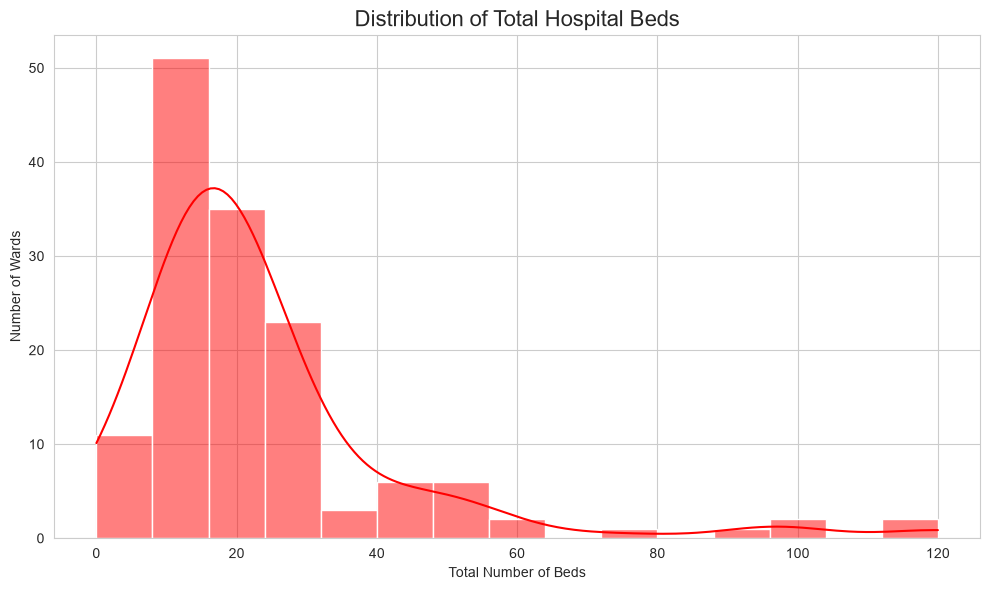

In [37]:
sns.set_style("whitegrid")

beds = df["Total no. of beds"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    beds,
    bins=15,
    kde=True,color="Red"
)

plt.title("Distribution of Total Hospital Beds", fontsize=16)
plt.xlabel("Total Number of Beds")
plt.ylabel("Number of Wards")

plt.tight_layout()
plt.savefig("distribution_total_hospital_beds.png", dpi=300, bbox_inches="tight")
plt.show()

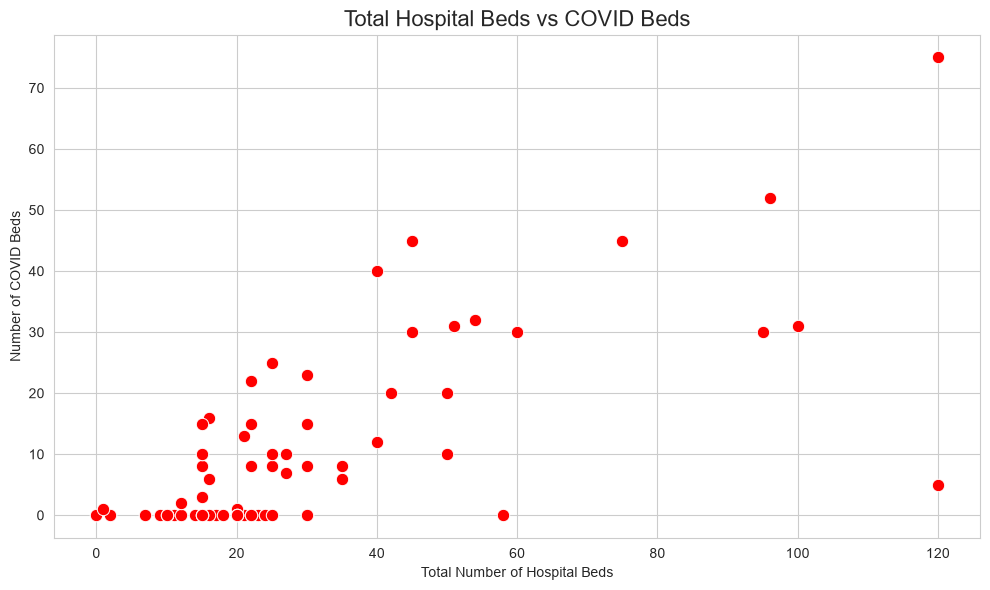

In [39]:
sns.set_style("whitegrid")
scatter_data = df[
    ["Total no. of beds", "Number of COVID beds"]
].dropna()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=scatter_data,
    x="Total no. of beds",
    y="Number of COVID beds",
    s=80,
    color="Red"
)

plt.title("Total Hospital Beds vs COVID Beds", fontsize=16)
plt.xlabel("Total Number of Hospital Beds")
plt.ylabel("Number of COVID Beds")

plt.tight_layout()
plt.savefig("total_hospital_beds_vs_covid_beds.png", dpi=300, bbox_inches="tight")
plt.show()

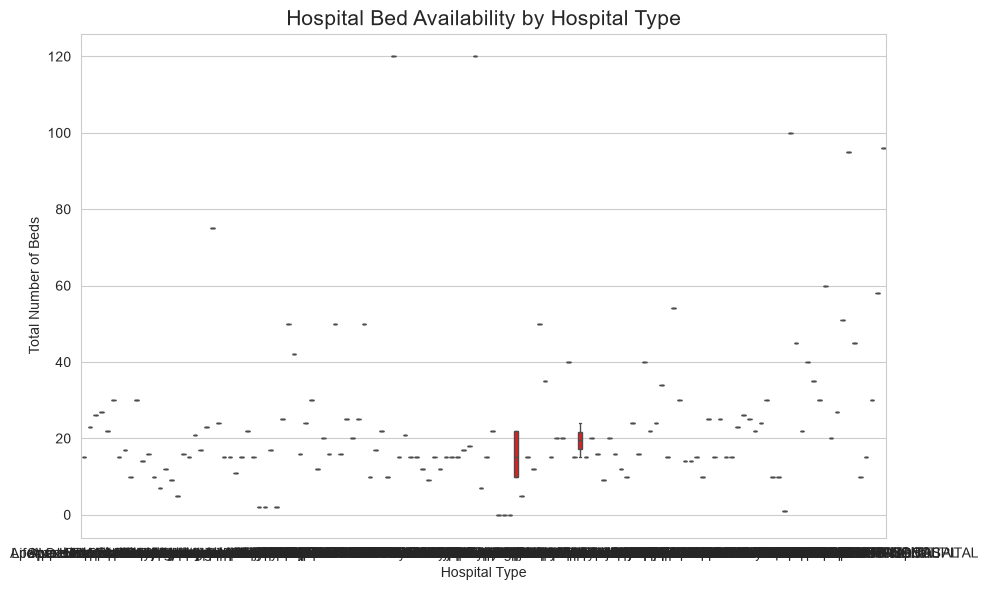

In [40]:
sns.set_style("whitegrid")

box_data = df[
    ["Type of hospital_PrivateorPublic", "Total no. of beds"]
].dropna()

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=box_data,
    x="Type of hospital_PrivateorPublic",
    y="Total no. of beds",color="Red"
)

plt.title("Hospital Bed Availability by Hospital Type", fontsize=15)
plt.xlabel("Hospital Type")
plt.ylabel("Total Number of Beds")

plt.tight_layout()
plt.savefig("hospital_bed_availability.png", dpi=300, bbox_inches="tight")
plt.show()

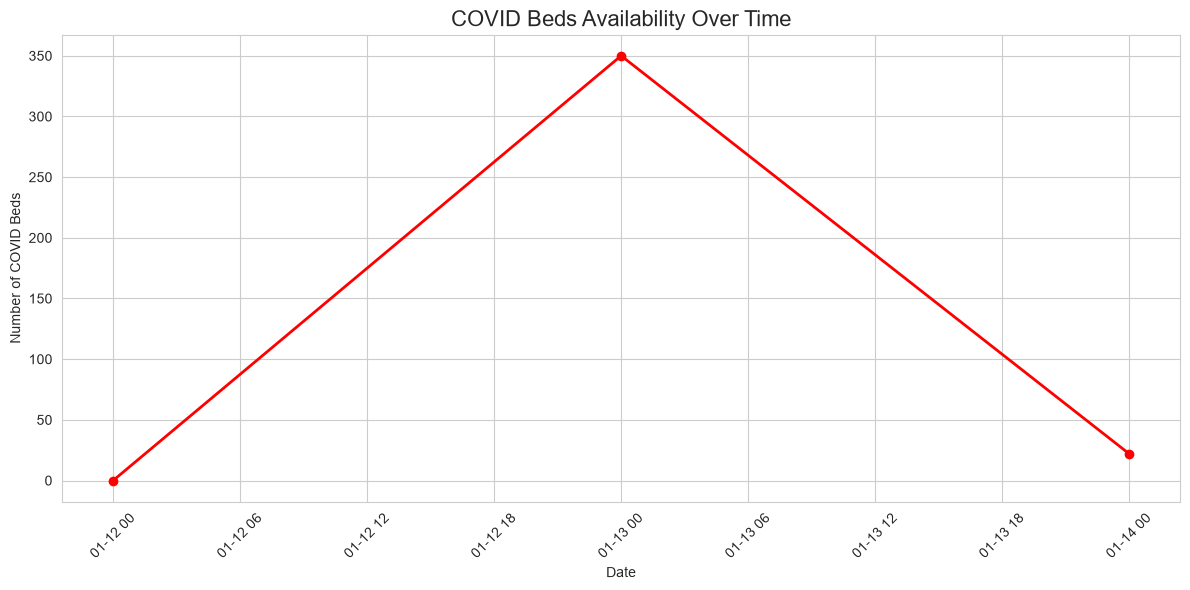

In [41]:
df["Day-Month-Year"] = pd.to_datetime(
    df["Day-Month-Year"],
    dayfirst=True,
    errors="coerce"
)

line_data = df[
    ["Day-Month-Year", "Number of COVID beds"]
].dropna()

daily_beds = line_data.groupby(
    "Day-Month-Year"
)["Number of COVID beds"].sum().sort_index()

plt.figure(figsize=(12, 6))

plt.plot(
    daily_beds.index,
    daily_beds.values,
    marker="o",
    linewidth=2,
    color="Red"
)

plt.title("COVID Beds Availability Over Time", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Number of COVID Beds")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.savefig("covid_beds_availability.png", dpi=300, bbox_inches="tight")
plt.show()